# Lab 2

## Problem 1

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

plt.rcParams["figure.figsize"] = (8,6)

### Poisson Distribution $ \frac{\lambda^k e^{-\lambda}}{k!} $
$ \lambda = \mu = $ number of events expected within time interval (cosmic ray background = __ )  
K = number of events actually observed

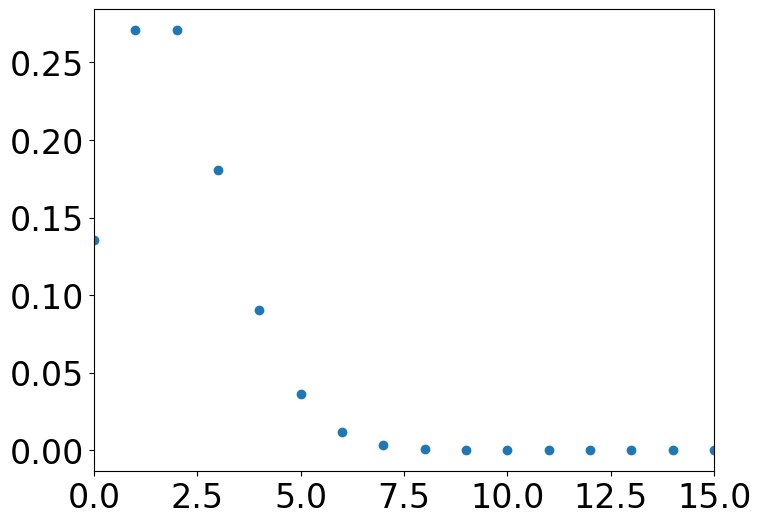

In [2]:
cosmic_ray_background = 2
gamma_ray_emissions = 4
k = np.arange(0,100)

#1 day PMF
one_day = stats.poisson.pmf(k = k, mu = cosmic_ray_background)
one_day

fig, ax = plt.subplots(1, 1)
plt.tick_params(labelsize = 24)
plt.xlim([0, 15])
plt.scatter(k, stats.poisson.pmf(k = k, mu = cosmic_ray_background))
plt.show()

### Show how the probability distribution of the background changes as you integrate (sum) for more days.

### Show that after 5 days, the summed probability distribution is still a Poisson distribution. Explain why this makes sense from a mathematical and conceptual point of view.

(0.0, 20.0)

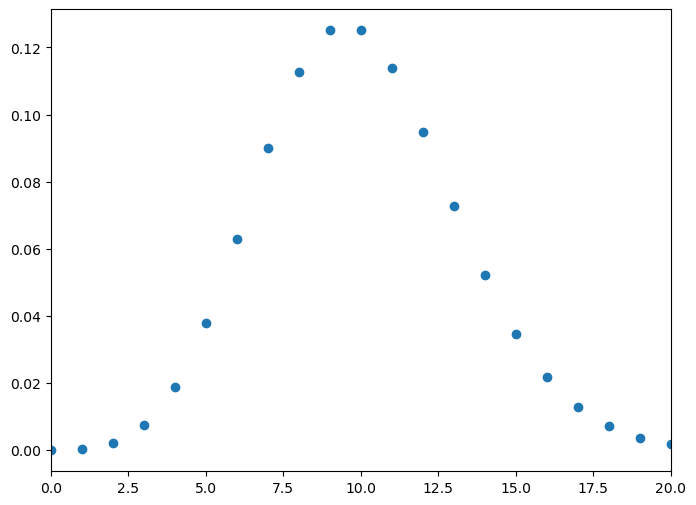

In [3]:
# Checking probability distribution after 5 days
days = 5

mu = cosmic_ray_background * days
k = k
p = stats.poisson.pmf(k, mu)

plt.scatter(k, p)
plt.xlim(0,20)

2
4
10
20
40


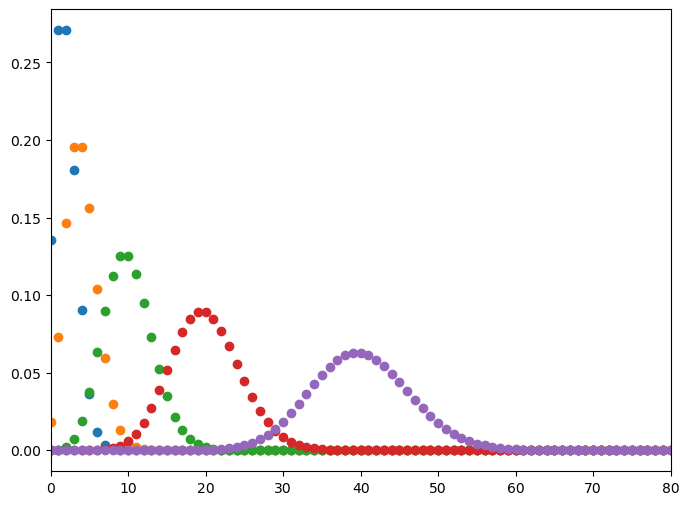

In [4]:
# Checking probability distribution after 1,2,5,10,100 days

days = [1,2,5,10,20]


for n in days:
    mu = cosmic_ray_background * n
    k = k
    p = stats.poisson.pmf(k, mu)
    print(mu)

    plt.scatter(k, p)
    plt.xlim(0,80)

## Part D

## Using the survival function we find that there is about a 0.05 probability of observing 4 gamma rays. Converting this to the equivalent sigma, we find there is a 2.619 sigma value associated with this observation.

In [5]:
# Calculating probability and sigma after m days

observed_gamma_rays = gamma_ray_emissions

#Using survival function to find 
after_m_days = stats.poisson.sf(gamma_ray_emissions, cosmic_ray_background)
print(after_m_days)

print(1 - stats.norm.ppf(after_m_days))

0.052653017343711125
2.6196567360165885


## Problem 2

## Rayleigh distribution centered at our cosmic ray background after 1 time interval

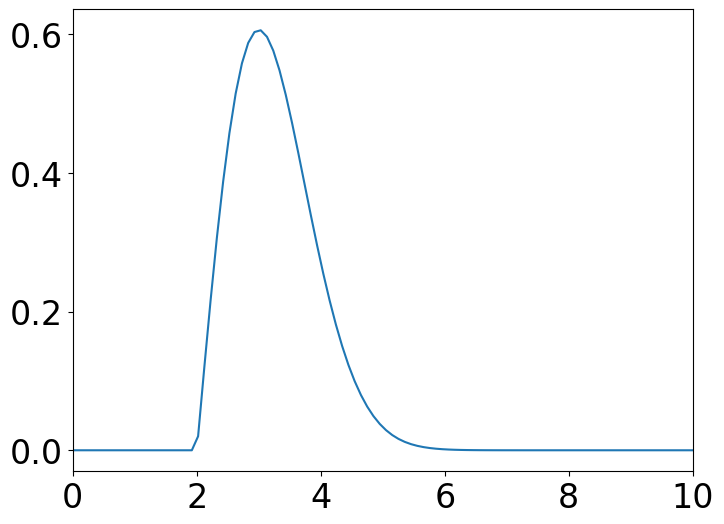

In [6]:
x = np.linspace(0,10, 100)
rayleigh_scale = 1

rayleigh = stats.rayleigh.pdf(x, cosmic_ray_background, scale=rayleigh_scale)

fig, ax = plt.subplots(1, 1)
plt.tick_params(labelsize = 24)
plt.xlim([0, 10])
ax.plot(x, stats.rayleigh.pdf(x = x, loc=cosmic_ray_background, scale=1))
plt.show()

## Show how the distribution changes as you average over more observing intervals

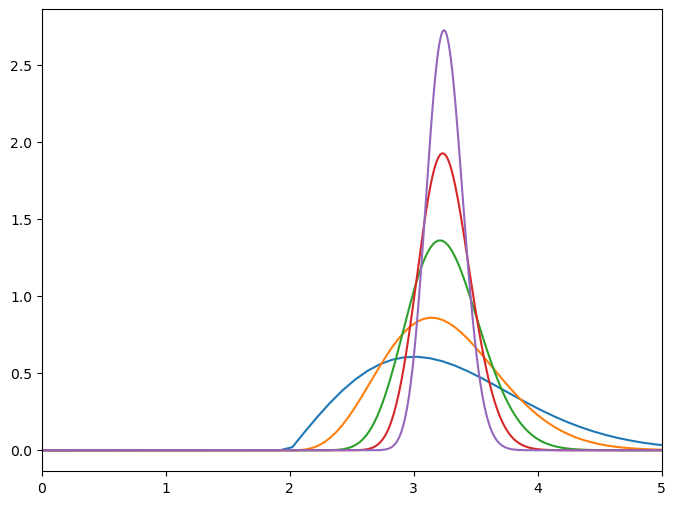

In [7]:
observing_interval = [1,2,5,10,20]
fig, ax = plt.subplots(1, 1)

for N in observing_interval:
    result = rayleigh.copy()
    for i in range(N - 1):
        result = np.convolve(result, rayleigh)
        
    x_avg = np.linspace(0, 10 * N, len(result)) / N
    p = result / (result.sum() * (x_avg[1] - x_avg[0]))

    ax.plot(x_avg, p)

ax.set_xlim(0, 5)
plt.show()

## At lower observing interals (around 1 to 10), the distribution still resembles a Rayleigh distribution. At higher observing intervals (20 or more), the distribution appears more Gaussian which is expected due to the central limit theorem.

## Problem 3a

In [8]:
background_x = 2
signal_y = 5

p1 = stats.norm.sf(signal_y, loc=0, scale=background_x) 
print(p1)

sigma = stats.norm.ppf(1 - p1) 
print(sigma)

0.006209665325776132
2.4999999999999987


### This signal reading y = 5 has a sigma value of 2.5, which is less than the 5 sigma that is needed to claim it as a discovery

## Problem 3b

## The statistical question we ask is: when looking at a Gaussian distribution of 10,000 pixels with mean 0 and scale 2, what is the probability distribution of the brightest pixel value in the sample?

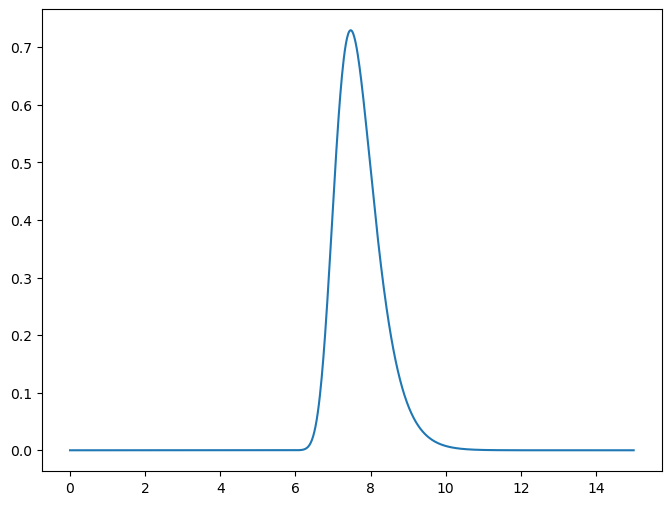

In [9]:
y = np.linspace(0, 15, 1000)
background_pdf = 10000 * stats.norm.pdf(y, 0, background_x) * stats.norm.cdf(y, 0, background_x)**(10000)

plt.plot(y, background_pdf)

plt.show()

## Problem 3c) Calculating brightest signal and sigma value

In [10]:
signal_p2 = 1 - stats.norm.cdf(signal_y, 0, background_x)**N
print(signal_p2)

signal_sigma2 = sigma = stats.norm.isf(signal_p2)
print(signal_sigma2)

0.1171328208818957
1.1894423559079565


### Our signal probability is 0.117 and our associated sigma is 1.18, which is lower than the version 1 scenario with the known signal, which is expected.

## Problem 4

## Version 1 signal required for 5 sigma:

In [11]:
N = 10000
p5 = stats.norm.sf(5)

signal_4a = stats.norm.isf(p5, 0, background_x)
print(signal_4a)
print(signal_4a / background_x)

10.000000000000002
5.000000000000001


A signal of 10 is required to have a sigma value of at least 5

## 4b

In [12]:
p5 = stats.norm.sf(5)

p_local = p5 / N
signal_4b = stats.norm.isf(p_local, 0, background_x)

print(signal_4b)

13.101075225410668


### 4c: For a sigma value of 5, version 1 needs a signal of 10 and version 2 needs a signal of 13.1, Which means the signal must be ~31% brighter if you have a trials factor of 10,000. The sensitivity penalty due to a trials factor is low because the extreme ends of the probability distribution fall off exponentially, so even with a large sample size, it is very unlikely for any to fall in these outer ranges.

### 4d) If you changed the trials factor significantly (orders of magnitude), how large is the effect on your 5-sigma sensitivity threshold?

In [13]:
N = 1000000

In [14]:
p5 = stats.norm.sf(5)

signal_4d = stats.norm.isf(p5 / N, 0, background_x)
print(signal_4d) 

14.413370486819629


With a sample size 2 orders of magnitude larger (1,000,000), the required signal strength is 14.4, only slightly higher than the signal strength for 10,000 sample size, which is expected due to the logarithmic nature of the probability distribution

## Extra Credit: Rayleigh Distribution

In [15]:
N = 10000
M = 1000000
rayleigh_1 = stats.rayleigh.isf(p5, scale=1)
rayleigh_N = stats.rayleigh.isf(p5 / N, scale=1)
rayleigh_M = stats.rayleigh.isf(p5 / M, scale=1)

print(rayleigh_1)
print(rayleigh_N)
print(rayleigh_M)

5.489079776062419
6.967831623391155
7.600066967067198


### In a Rayleigh distribution where you only observe 1 pixel, the signal strength is 5.49. 

### When you increase the sample to 10,000 pixels, the signal strength required is 6.9.  

### When you increase the sample to 1,000,000 pixels, the signal strength required is 7.6

The outer ends of the Rayleigh distribution also fall off exponentially, similar to the Gaussian distribution, but at a different rate. As we increase the sample size by orders of magnitude, the required signal size doesn't grow much